<Axes: >

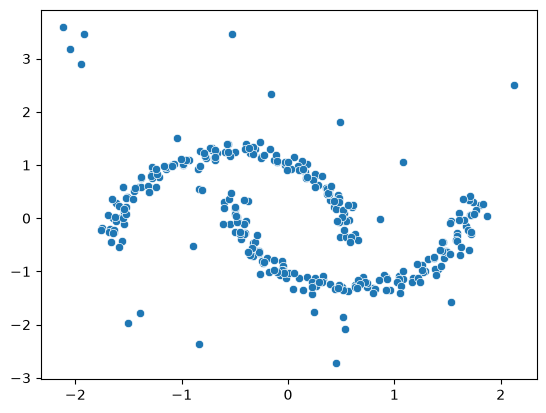

In [6]:
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
import seaborn as sns


# 1. Generate non-linear moon-shaped data and inject random anomalies
X_normal, _ = make_moons(n_samples=300, noise=0.05, random_state=42)

# Injecting random noise/anomalies spread across the coordinate space
np.random.seed(42)
X_anomalies = np.random.uniform(low=-1.5, high=2.5, size=(25, 2))
X = np.vstack([X_normal, X_anomalies])

# 2. Scale features (Critical: ensures distance calculations are uniform)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

sns.scatterplot(x=X_scaled[:,0],y=X_scaled[:,1])

In [1]:
# 3. Fit DBSCAN
# Adjusted eps for the scaled moon distribution
dbscan = DBSCAN(eps=0.25, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

# 4. Extract anomalies (DBSCAN labels noise points as -1)
df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])
df['Cluster_Label'] = labels
df['Is_Anomaly'] = (labels == -1)

# Summary Output
print(f"Total data points: {len(df)}")
print(f"Anomalies detected: {df['Is_Anomaly'].sum()}")
print(f"Valid clusters found (excluding anomalies): {len(set(labels)) - (1 if -1 in labels else 0)}")

print("\nSample of detected anomalies:")
print(df[df['Is_Anomaly'] == True].head())

Total data points: 325
Anomalies detected: 22
Valid clusters found (excluding anomalies): 2

Sample of detected anomalies:
     Feature_1  Feature_2  Cluster_Label  Is_Anomaly
300  -0.001840   2.302857             -1        True
301   1.427976   0.894634             -1        True
302  -0.875925  -0.876022             -1        True
303  -1.267666   1.964705             -1        True
304   0.904460   1.332290             -1        True


<Axes: >

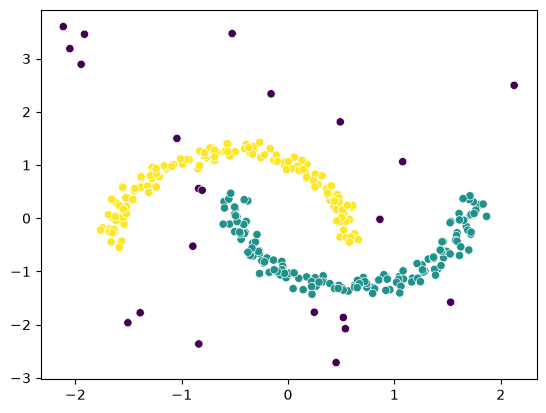

In [7]:
sns.scatterplot(x=X_scaled[:,0],y=X_scaled[:,1],c=labels)

TypeError: float() argument must be a string or a real number, not 'LocalOutlierFactor'

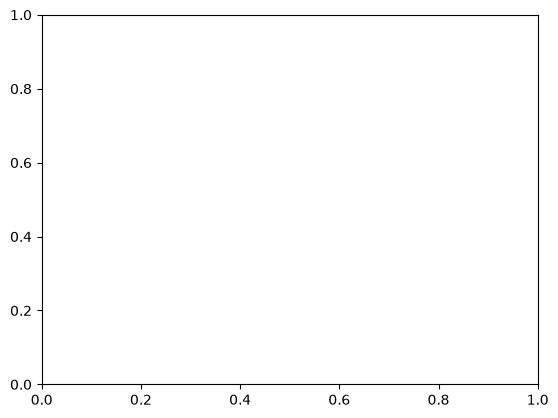